In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes

# Load dataset
data = load_diabetes()

# Features
X = pd.DataFrame(data.data, columns=data.feature_names)

# Original continuous target
y_original = data.target

# Convert target into binary classes
# 1 = Diabetes, 0 = No Diabetes
y = (y_original > np.median(y_original)).astype(int)

print("Dataset loaded successfully!")

print("\nFirst 5 rows:")
print(X.head())

print("\nDataset shape:")
print(X.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nClass distribution:")
print(pd.Series(y).value_counts())

Dataset loaded successfully!

First 5 rows:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  

Dataset shape:
(442, 10)

Features:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Class distribution:
1    221
0    221
Name: count, dtype: int64


In [3]:
print("\nFeature Information:")
print(X.info())

print("\nStatistical Summary:")
print(X.describe())


Feature Information:
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB
None

Statistical Summary:
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.1239

In [4]:
df = X.copy()
df["Diagnosis"] = y

print(df.head())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  Diagnosis  
0 -0.002592  0.019907 -0.017646          1  
1 -0.039493 -0.068332 -0.092204          0  
2 -0.002592  0.002861 -0.025930          1  
3  0.034309  0.022688 -0.009362          1  
4 -0.002592 -0.031988 -0.046641          0  


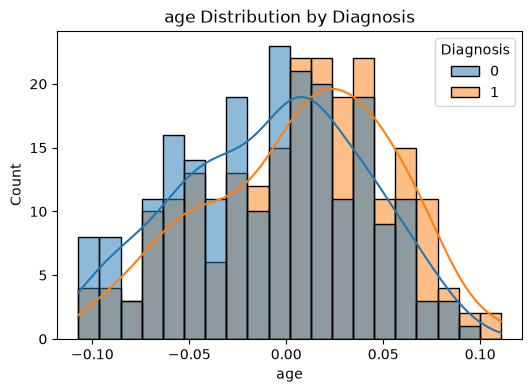

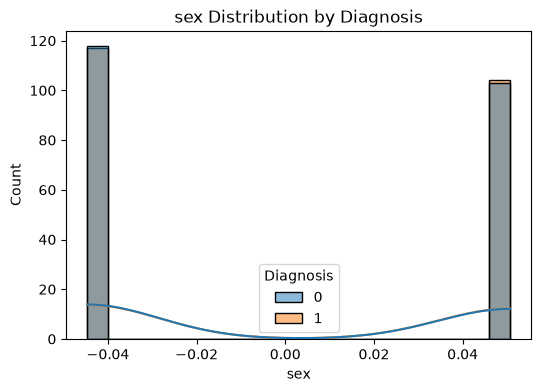

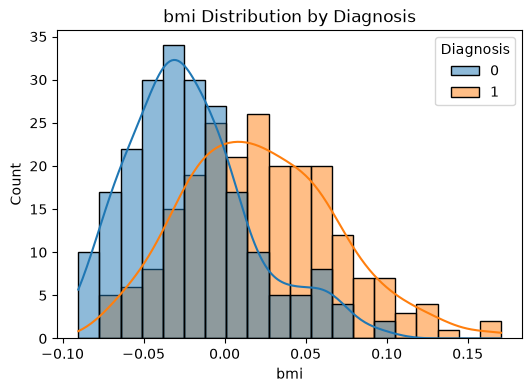

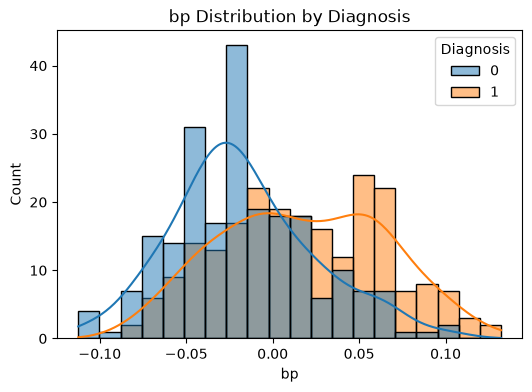

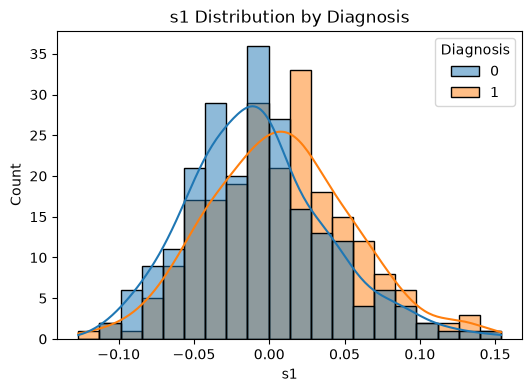

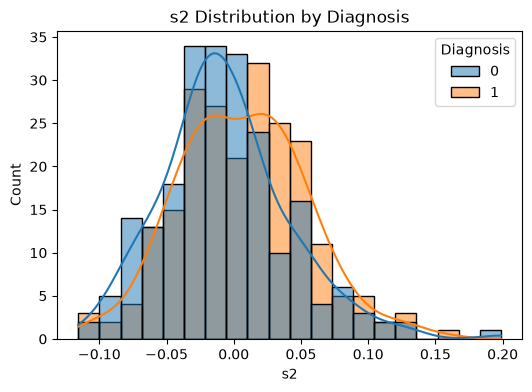

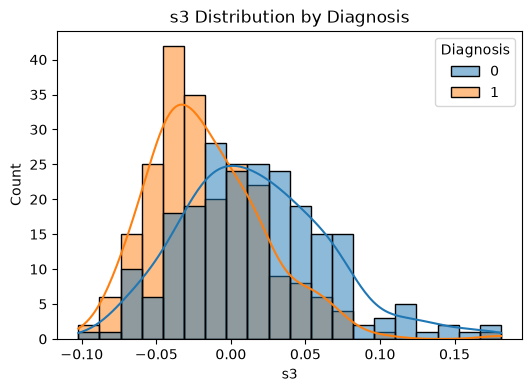

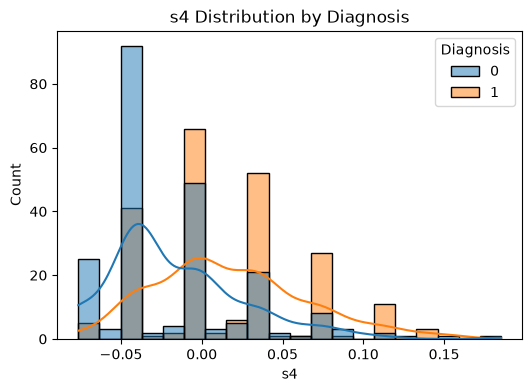

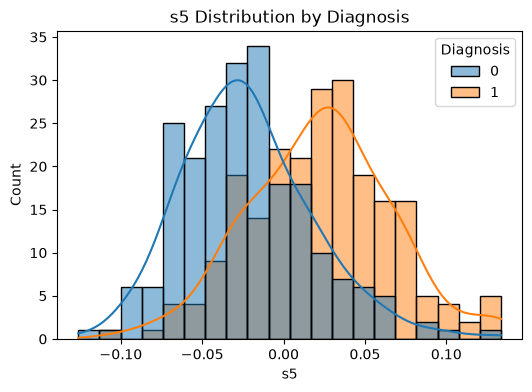

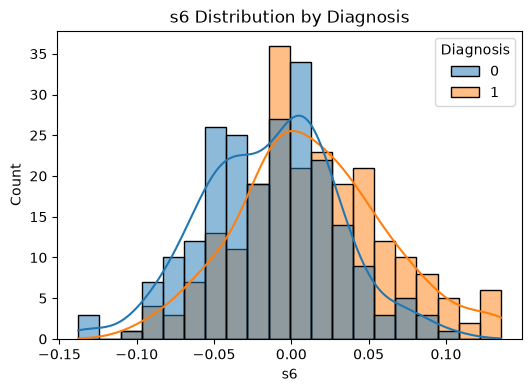

In [6]:
for feature in X.columns:
    plt.figure(figsize=(6, 4))

    sns.histplot(
        data=df,
        x=feature,
        hue="Diagnosis",
        kde=True,
        bins=20
    )

    plt.title(feature + " Distribution by Diagnosis")
    plt.show()

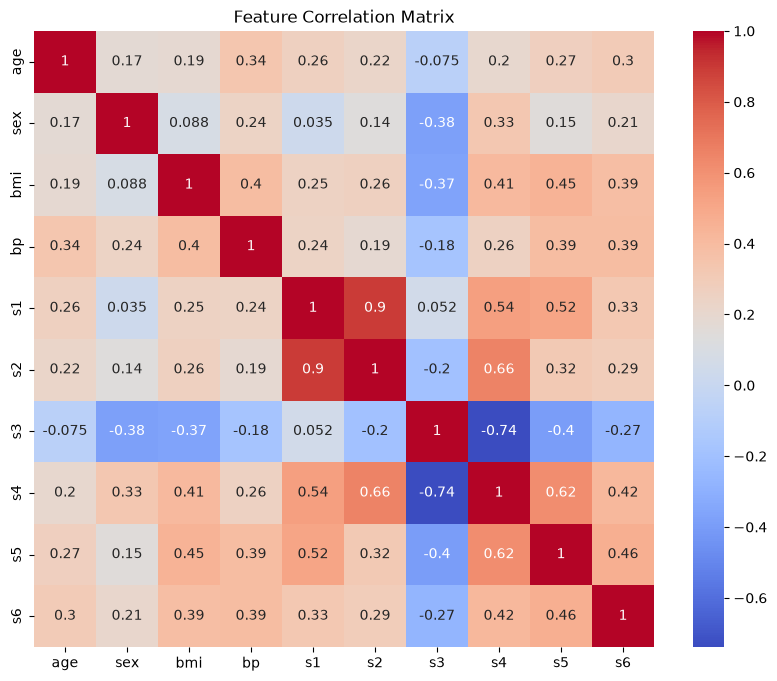

In [7]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation Matrix")
plt.show()

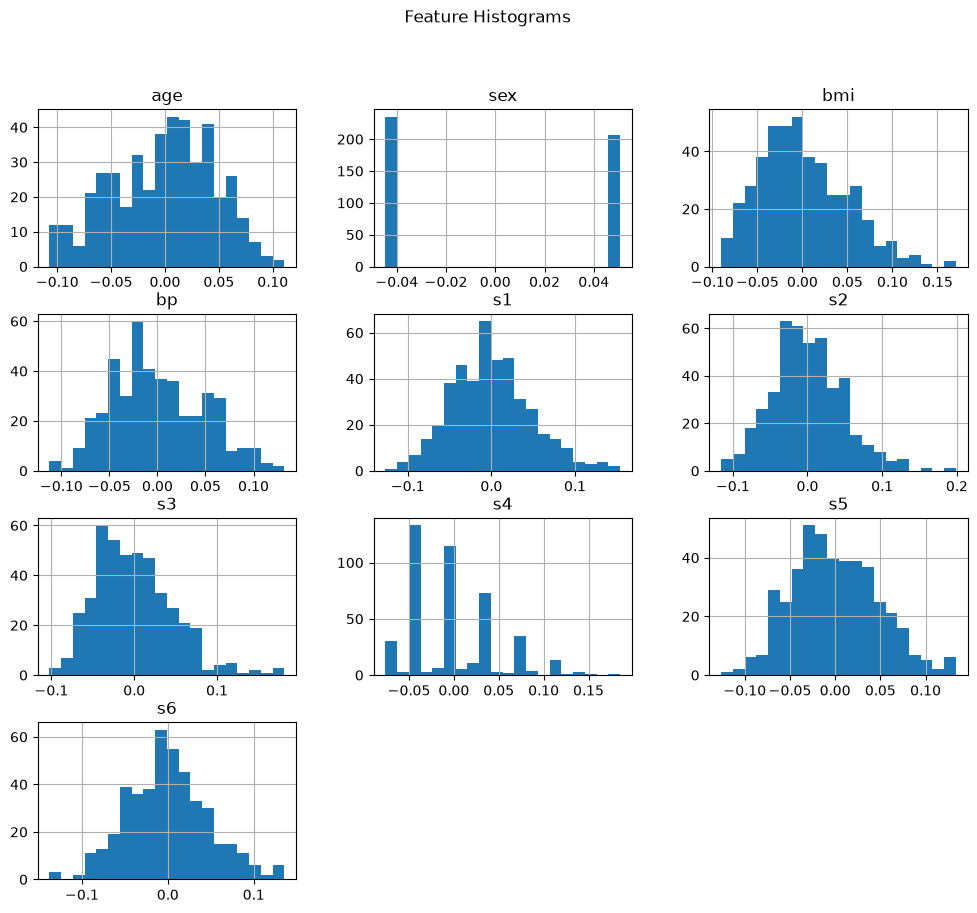

In [8]:
X.hist(
    figsize=(12, 10),
    bins=20
)

plt.suptitle("Feature Histograms")
plt.show()

In [ ]:
def multivariate_gaussian_pdf(x, mean, covariance):
    
    x = np.array(x)
    mean = np.array(mean)
    covariance = np.array(covariance)

    n = len(mean)

    covariance_inv = np.linalg.inv(covariance)

    determinant = np.linalg.det(covariance)

    exponent = -0.5 * np.dot(
        np.dot((x - mean), covariance_inv),
        (x - mean)
    )


    coefficient = 1 / np.sqrt(
        (2 * np.pi) ** n * determinant
    )

    return coefficient * np.exp(exponent)

In [8]:
mean = np.array([0, 0])

covariance = np.array([
    [1, 0],
    [0, 1]
])

x = np.array([0, 0])

probability = multivariate_gaussian_pdf(
    x,
    mean,
    covariance
)

print("Gaussian PDF value:", probability)

Gaussian PDF value: 0.15915494309189535


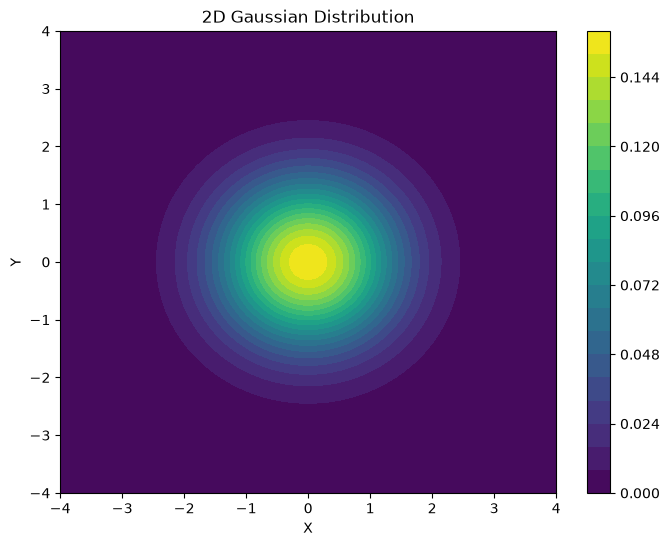

In [9]:
x = np.linspace(-4, 4, 100)
y_grid = np.linspace(-4, 4, 100)

X_grid, Y_grid = np.meshgrid(x, y_grid)

mean = np.array([0, 0])

covariance = np.array([
    [1, 0],
    [0, 1]
])

Z = np.zeros(X_grid.shape)

for i in range(X_grid.shape[0]):
    for j in range(X_grid.shape[1]):
        point = np.array([
            X_grid[i, j],
            Y_grid[i, j]
        ])

        Z[i, j] = multivariate_gaussian_pdf(
            point,
            mean,
            covariance
        )

plt.figure(figsize=(8, 6))

plt.contourf(
    X_grid,
    Y_grid,
    Z,
    levels=20
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("2D Gaussian Distribution")
plt.colorbar()

plt.show()

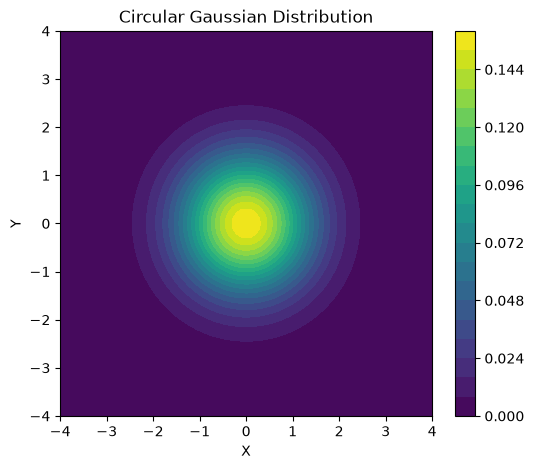

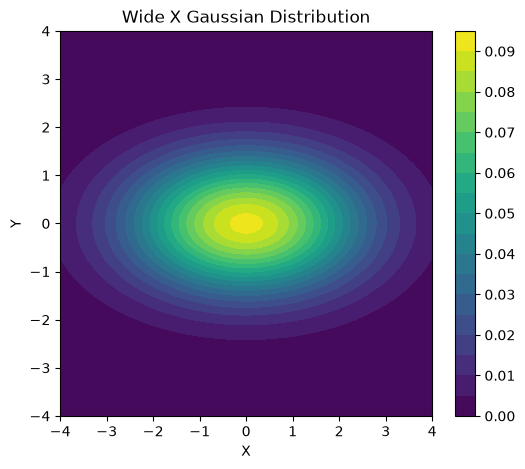

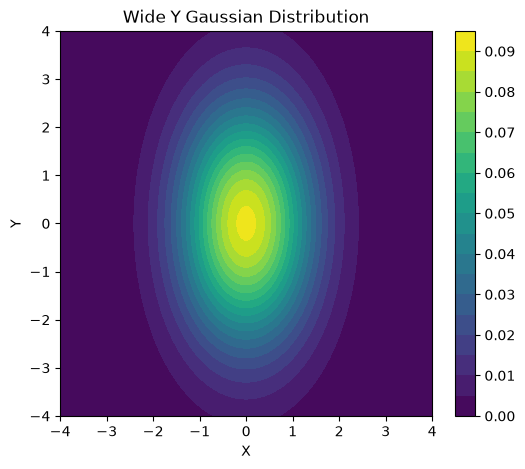

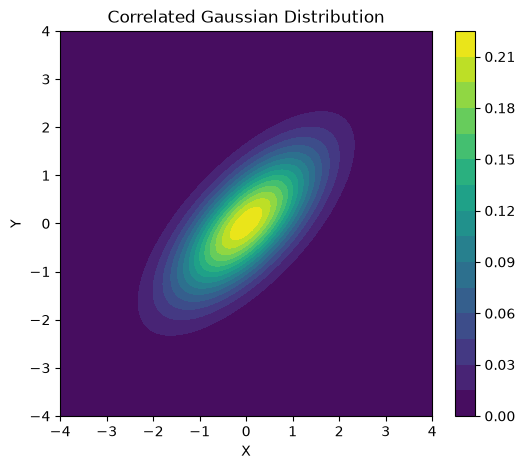

In [10]:
cov4 = np.array([
    [1, 0.7],
    [0.7, 1]
])

cov3 = np.array([
    [1, 0],
    [0, 3]
])

cov2 = np.array([
    [3, 0],
    [0, 1]
])

cov1 = np.array([
    [1, 0],
    [0, 1]
])

covariances = [
    cov1,
    cov2,
    cov3,
    cov4
]

titles = [
    "Circular",
    "Wide X",
    "Wide Y",
    "Correlated"
]

for covariance, title in zip(covariances, titles):

    Z = np.zeros(X_grid.shape)

    for i in range(X_grid.shape[0]):
        for j in range(X_grid.shape[1]):

            point = np.array([
                X_grid[i, j],
                Y_grid[i, j]
            ])

            Z[i, j] = multivariate_gaussian_pdf(
                point,
                mean,
                covariance
            )

    plt.figure(figsize=(6, 5))

    plt.contourf(
        X_grid,
        Y_grid,
        Z,
        levels=20
    )

    plt.title(title + " Gaussian Distribution")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.colorbar()

    plt.show()

In [11]:
import numpy as np

# Split data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Separate classes
X0 = X_train[y_train == 0]
X1 = X_train[y_train == 1]

# Mean of each class
mean0 = np.mean(X0, axis=0)
mean1 = np.mean(X1, axis=0)

# Covariance of each class
cov0 = np.cov(X0, rowvar=False)
cov1 = np.cov(X1, rowvar=False)

# Within-class covariance
Sw = cov0 + cov1

# Inverse of within-class covariance
Sw_inv = np.linalg.inv(Sw)

# LDA direction
w = Sw_inv @ (mean1 - mean0)

# Prediction function
def lda_predict(X):
    scores = X @ w
    threshold = (mean0 + mean1) @ w / 2
    return (scores > threshold).astype(int)

# Predict
y_pred = lda_predict(X_test)

# Accuracy
accuracy = np.mean(y_pred == y_test)

print("LDA Accuracy:", accuracy)

LDA Accuracy: 0.7191011235955056


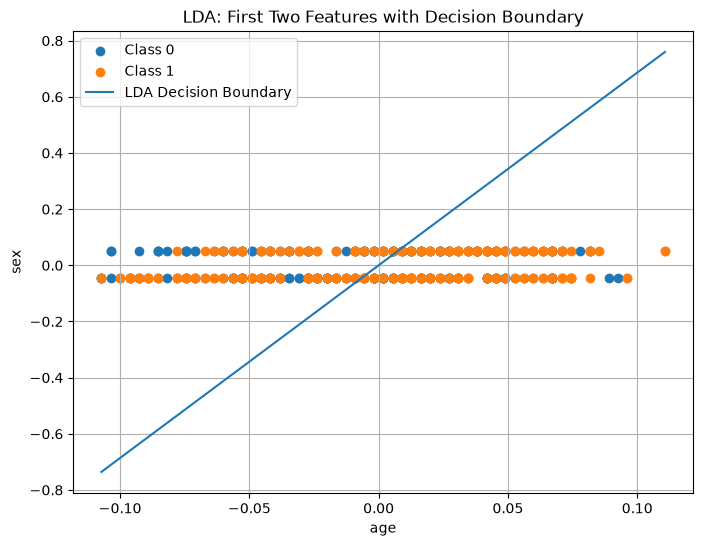

In [12]:


# Take first two features
X_2d = X.iloc[:, 0:2].values

# Separate classes
X0 = X_2d[y == 0]
X1 = X_2d[y == 1]

# Calculate means
mean0 = np.mean(X0, axis=0)
mean1 = np.mean(X1, axis=0)

# Calculate covariance
cov0 = np.cov(X0, rowvar=False)
cov1 = np.cov(X1, rowvar=False)

# Within-class scatter
Sw = cov0 + cov1

# LDA direction
w = np.linalg.inv(Sw) @ (mean1 - mean0)

# Decision boundary
# w1*x + w2*y = threshold
threshold = (mean0 + mean1) @ w / 2

# Create x values
x_values = np.linspace(X_2d[:, 0].min(), X_2d[:, 0].max(), 100)

# Calculate y values
y_values = (threshold - w[0] * x_values) / w[1]

# Plot actual class distributions
plt.figure(figsize=(8, 6))

plt.scatter(X0[:, 0], X0[:, 1], label="Class 0")
plt.scatter(X1[:, 0], X1[:, 1], label="Class 1")

# Plot decision boundary
plt.plot(x_values, y_values, label="LDA Decision Boundary")

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("LDA: First Two Features with Decision Boundary")
plt.legend()
plt.grid()
plt.show()

In [14]:
# Confusion matrix values
TP = np.sum((y_test == 1) & (y_pred == 1))
TN = np.sum((y_test == 0) & (y_pred == 0))
FP = np.sum((y_test == 0) & (y_pred == 1))
FN = np.sum((y_test == 1) & (y_pred == 0))

# Metrics
accuracy = (TP + TN) / (TP + TN + FP + FN)

precision = TP / (TP + FP)

recall = TP / (TP + FN)

specificity = TN / (TN + FP)

f1 = 2 * precision * recall / (precision + recall)

print("TP:", TP)
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall / Sensitivity:", recall)
print("Specificity:", specificity)
print("F1-score:", f1)

TP: 28
TN: 36
FP: 13
FN: 12
Accuracy: 0.7191011235955056
Precision: 0.6829268292682927
Recall / Sensitivity: 0.7
Specificity: 0.7346938775510204
F1-score: 0.6913580246913581


In [26]:


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Convert to NumPy arrays
X_train = X_train.values
X_test = X_test.values
y_train = np.array(y_train)
y_test = np.array(y_test)


# ============================================================
# 2. LDA CALCULATION
# ============================================================

# Separate classes
X0 = X_train[y_train == 0]
X1 = X_train[y_train == 1]

# Mean of each class
mean0 = np.mean(X0, axis=0)
mean1 = np.mean(X1, axis=0)

# Covariance of each class
cov0 = np.cov(X0, rowvar=False)
cov1 = np.cov(X1, rowvar=False)

# Within-class covariance
Sw = cov0 + cov1

# Inverse
Sw_inv = np.linalg.inv(Sw)

# LDA direction
w = Sw_inv @ (mean1 - mean0)

print("Number of features:", X_train.shape[1])
print("LDA weight shape:", w.shape)


# ============================================================
# 3. LDA PREDICTION
# ============================================================

scores = X_test @ w

threshold = (mean0 + mean1) @ w / 2

y_pred = (scores > threshold).astype(int)

accuracy = np.mean(y_pred == y_test)

print("\n--- LDA Results ---")
print("LDA Accuracy:", accuracy)





# ============================================================
# 5. FALSE POSITIVE VS FALSE NEGATIVE COST
# ============================================================

FP_cost = 1
FN_cost = 5

total_FP_cost = FP * FP_cost
total_FN_cost = FN * FN_cost

print("\n--- Medical Cost Analysis ---")
print("False Positive Cost:", total_FP_cost)
print("False Negative Cost:", total_FN_cost)
print("Total Medical Cost:", total_FP_cost + total_FN_cost)


# ============================================================
# 6. THRESHOLD OPTIMIZATION
# ============================================================

print("\n--- Threshold Optimization ---")

# Convert LDA scores to 0-1 range
score_min = scores.min()
score_max = scores.max()

probability = (scores - score_min) / (score_max - score_min)

thresholds = [0.3, 0.5, 0.7]

for t in thresholds:

    prediction = (probability >= t).astype(int)

    TP_t = np.sum((y_test == 1) & (prediction == 1))
    TN_t = np.sum((y_test == 0) & (prediction == 0))
    FP_t = np.sum((y_test == 0) & (prediction == 1))
    FN_t = np.sum((y_test == 1) & (prediction == 0))

    sensitivity = TP_t / (TP_t + FN_t)
    specificity_t = TN_t / (TN_t + FP_t)

    medical_cost = (FP_t * FP_cost) + (FN_t * FN_cost)

    print("\nThreshold:", t)
    print("TP:", TP_t)
    print("TN:", TN_t)
    print("FP:", FP_t)
    print("FN:", FN_t)
    print("Sensitivity:", sensitivity)
    print("Specificity:", specificity_t)
    print("Medical Cost:", medical_cost)


# ============================================================
# 7. EQUAL COVARIANCE ASSUMPTION
# ============================================================

print("\n--- Equal Covariance Assumption ---")

print("Class 0 Covariance:")
print(cov0)

print("\nClass 1 Covariance:")
print(cov1)

cov_difference = np.abs(cov0 - cov1)

average_difference = np.mean(cov_difference)

print("\nAverage Covariance Difference:", average_difference)

if average_difference < 0.01:
    print("Covariance matrices are approximately equal.")
else:
    print("Covariance matrices are different.")


# ============================================================
# 8. LOGISTIC REGRESSION COMPARISON
# ============================================================

logistic = LogisticRegression(max_iter=1000)

logistic.fit(X_train, y_train)

logistic_pred = logistic.predict(X_test)

logistic_accuracy = np.mean(logistic_pred == y_test)

print("\n--- LDA vs Logistic Regression ---")
print("LDA Accuracy:", accuracy)
print("Logistic Regression Accuracy:", logistic_accuracy)

if accuracy > logistic_accuracy:
    print("LDA performed better.")

elif logistic_accuracy > accuracy:
    print("Logistic Regression performed better.")

else:
    print("Both models performed equally.")

Number of features: 10
LDA weight shape: (10,)

--- LDA Results ---
LDA Accuracy: 0.7191011235955056

--- Medical Cost Analysis ---
False Positive Cost: 13
False Negative Cost: 60
Total Medical Cost: 73

--- Threshold Optimization ---

Threshold: 0.3
TP: 38
TN: 33
FP: 16
FN: 2
Sensitivity: 0.95
Specificity: 0.673469387755102
Medical Cost: 26

Threshold: 0.5
TP: 22
TN: 43
FP: 6
FN: 18
Sensitivity: 0.55
Specificity: 0.8775510204081632
Medical Cost: 96

Threshold: 0.7
TP: 4
TN: 49
FP: 0
FN: 36
Sensitivity: 0.1
Specificity: 1.0
Medical Cost: 180

--- Equal Covariance Assumption ---
Class 0 Covariance:
[[ 2.21306711e-03  2.84135172e-04  3.97815345e-04  4.36332544e-04
   7.93510227e-04  7.89641160e-04  5.12219363e-05  3.98661281e-04
   3.64485011e-04  5.56793177e-04]
 [ 2.84135172e-04  2.28453430e-03  4.29965183e-05  3.73710533e-04
   4.55209891e-05  4.24918536e-04 -9.10240645e-04  7.58620085e-04
   4.68621600e-05  4.22755261e-04]
 [ 3.97815345e-04  4.29965183e-05  1.35193806e-03  3.76885047